In [2]:
import pandas as pd
df = pd.read_csv("Salary_Data.csv")
df.head()

,Age,Gender,Education Level,Job Title,Years of Experience,Salary
0,32.0,Male,Bachelor's,Software Engineer,5.0,90000.0
1,28.0,Female,Master's,Data Analyst,3.0,65000.0
2,45.0,Male,PhD,Senior Manager,15.0,150000.0
3,36.0,Female,Bachelor's,Sales Associate,7.0,60000.0
4,52.0,Male,Master's,Director,20.0,200000.0


In [3]:
df.isnull().sum()

Age                    2
Gender                 2
Education Level        3
Job Title              2
Years of Experience    3
Salary                 5
dtype: int64

In [4]:
df.describe()

,Age,Years of Experience,Salary
count,6702.000000,6701.000000,6699.000000
mean,33.620859,8.094687,115326.964771
std,7.614633,6.059003,52786.183911
min,21.000000,0.000000,350.000000
25%,28.000000,3.000000,70000.000000
50%,32.000000,7.000000,115000.000000
75%,38.000000,12.000000,160000.000000
max,62.000000,34.000000,250000.000000


In [5]:
df["Age"].mode()

0    27.0
Name: Age, dtype: float64

In [6]:
df = df.dropna(subset=["Salary"])

In [7]:
df.isnull().sum()

Age                    0
Gender                 0
Education Level        1
Job Title              0
Years of Experience    0
Salary                 0
dtype: int64

In [8]:
y = df["Salary"]
X = df.drop(columns=["Salary"])

In [9]:
X.shape,y.shape


((6699, 5), (6699,))

In [10]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

In [11]:
X_train.shape, X_test.shape

((5359, 5), (1340, 5))

In [12]:
sayisal_veri = X_train[["Age", "Years of Experience"]].join(y_train)
korelasyon = sayisal_veri.corr()
korelasyon

,Age,Years of Experience,Salary
Age,1.000000,0.935816,0.726062
Years of Experience,0.935816,1.000000,0.806973
Salary,0.726062,0.806973,1.000000


<Axes: >

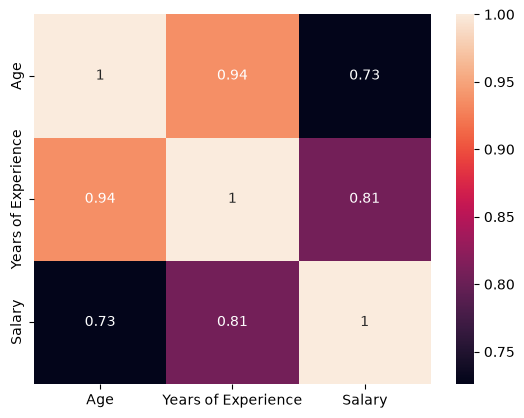

In [13]:
import seaborn as sns
sns.heatmap(korelasyon,annot=True)

In [14]:
X_train_deneyim = X_train[["Years of Experience"]]
X_train_deneyim.shape

(5359, 1)

In [15]:
X_train_yas_deneyim = X_train[["Age","Years of Experience"]]
X_train_yas_deneyim.shape

(5359, 2)

In [16]:
X_fit, X_val, y_fit, y_val = train_test_split(
    X_train_yas_deneyim, y_train, test_size=0.2, random_state=42
)

In [17]:
X_fit.shape, X_val.shape

((4287, 2), (1072, 2))

In [18]:
from sklearn.linear_model import LinearRegression

model_deneyim = LinearRegression()

In [19]:
model_deneyim.fit(X_fit[["Years of Experience"]], y_fit)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](1,)",[7071.03]
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Defined only when `X`has feature names that are all strings... versionadded:: 1.0","ndarray[object](1,)",['Years of Experience']
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.",float64,5.847e+04
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,1
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int64,np.int64(1)


In [20]:
tahmin_deneyim = model_deneyim.predict(X_val[["Years of Experience"]])

In [21]:
model_yas_deneyim = LinearRegression()
model_yas_deneyim.fit(X_fit, y_fit)
tahmin_yas_deneyim = model_yas_deneyim.predict(X_val)

In [22]:
model_yas_deneyim = LinearRegression()
model_yas_deneyim.fit(X_fit, y_fit)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](2,)","[-1783.11, 9172.82]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Defined only when `X`has feature names that are all strings... versionadded:: 1.0","ndarray[object](2,)","['Age','Years of Experience']"
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.",float64,1.014e+05
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,2
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int64,np.int64(2)


In [23]:
tahmin_yas_deneyim = model_yas_deneyim.predict(X_val)
tahmin_yas_deneyim[:5]

array([265534.49847694, 151122.72433933,  64229.39735945, 147556.49946994,
        71619.100644  ])

In [24]:
from sklearn.metrics import mean_absolute_error
mae_deneyim = mean_absolute_error(y_val, tahmin_deneyim)
mae_yas_deneyim = mean_absolute_error(y_val, tahmin_yas_deneyim)
mae_deneyim, mae_yas_deneyim


(24548.098409027105, 24419.989240713974)

Yaşın maaş tahminine katkısı

Korelasyon tablosunda yaş ile deneyim yılı arasında güçlü bir ilişki gördüm (0,94). Yaşın ek katkısını ölçmek için aynı doğrulama grubunda iki doğrusal regresyon modelini karşılaştırdım. Yalnızca deneyim yılı kullanan modelin MAE’si 24.548,10, yaş ve deneyimi birlikte kullanan modelin MAE’si 24.419,99 oldu. Bu doğrulama grubunda yaş eklemek ortalama mutlak hatayı 128,11 (yaklaşık %0,52) azalttı.

In [25]:
X_train["Job Title"].value_counts().head(10)

Job Title
Software Engineer            423
Data Scientist               358
Software Engineer Manager    301
Data Analyst                 287
Senior Project Engineer      259
Product Manager              250
Full Stack Engineer          240
Marketing Manager            214
Senior Software Engineer     202
Back end Developer           191
Name: count, dtype: int64

In [26]:
X_fit_unvan = X_fit.join(X_train["Job Title"])
X_fit_unvan.head()

,Age,Years of Experience,Job Title
3291,41.0,16.0,Director of Data Science
4800,26.0,2.0,Junior Sales Associate
2007,42.0,13.0,Software Engineer Manager
3767,30.0,4.0,Human Resources Coordinator
5590,30.0,5.0,Marketing Coordinator


In [27]:
X_val_unvan = X_val.join(X_train["Job Title"])
X_val_unvan.head()

,Age,Years of Experience,Job Title
2636,52.0,28.0,Senior Project Engineer
4829,39.0,13.0,Senior Research Scientist
6619,26.0,1.0,Sales Executive
4074,41.0,13.0,Human Resources Manager
1504,27.0,2.0,Back end Developer


In [28]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import OneHotEncoder

on_isleme = ColumnTransformer(
    [("unvan", OneHotEncoder(handle_unknown="ignore"), ["Job Title"])],
    remainder="passthrough",
)

model_unvan = make_pipeline(on_isleme, LinearRegression())
model_unvan.fit(X_fit_unvan, y_fit)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('columntransformer', ...), ('linearregression', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](3,)","['Age','Years of Experience','Job Title']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,3
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('unvan', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the out

In [29]:
tahmin_unvan = model_unvan.predict(X_val_unvan)
mae_unvan = mean_absolute_error(y_val, tahmin_unvan)

mae_yas_deneyim, mae_unvan

(24419.989240713974, 15807.332285720493)

Yaş ve deneyim yılına iş unvanını ekledim. İş unvanlarını one-hot encoding ile kodladım ve aynı doğrulama satırlarında iki doğrusal regresyon modelini karşılaştırdım. İş unvanı eklendiğinde MAE 24.419,99’dan 15.807,33’e düştü.

In [30]:
X_train["Education Level"].value_counts(dropna=False)

Education Level
Bachelor's Degree    1828
Master's Degree      1259
PhD                  1091
Bachelor's            610
High School           351
Master's              218
phD                     1
NaN                     1
Name: count, dtype: int64

In [31]:
egitim_seviyesi = X_train["Education Level"].replace({
    "Bachelor's": "Bachelor's Degree",
    "Master's": "Master's Degree",
    "phD": "PhD",
}).fillna("Unknown")

egitim_seviyesi.value_counts()

Education Level
Bachelor's Degree    2438
Master's Degree      1477
PhD                  1092
High School           351
Unknown                 1
Name: count, dtype: int64

In [32]:
X_fit_egitim = X_fit_unvan.join(egitim_seviyesi)
X_val_egitim = X_val_unvan.join(egitim_seviyesi)

X_fit_egitim.shape, X_val_egitim.shape

((4287, 4), (1072, 4))

In [33]:
on_isleme_egitim = ColumnTransformer(
    [
        (
            "kategoriler",
            OneHotEncoder(handle_unknown="ignore"),
            ["Job Title", "Education Level"],
        )
    ],
    remainder="passthrough",
)

model_egitim = make_pipeline(on_isleme_egitim, LinearRegression())
model_egitim.fit(X_fit_egitim, y_fit)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('columntransformer', ...), ('linearregression', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](4,)","['Age','Years of Experience','Job Title','Education Level']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,4
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('kategoriler', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis c

In [34]:
tahmin_egitim = model_egitim.predict(X_val_egitim)
mae_egitim = mean_absolute_error(y_val, tahmin_egitim)

mae_unvan, mae_egitim

(15807.332285720493, 15784.310818973792)

Eğitim seviyesi sütunundaki farklı yazımları birleştirdim ve eksik değeri Unknown olarak işaretledim. Bu sütunu modele eklediğimde aynı doğrulama grubunda MAE 15.807,33’ten 15.784,31’e düştü. Eğitim seviyesinin bu modeldeki ek katkısı sınırlı kaldı.

In [35]:
from sklearn.base import clone
from sklearn.ensemble import RandomForestRegressor

model_oran = make_pipeline(
    clone(on_isleme_egitim),
    RandomForestRegressor(n_estimators=150, random_state=42, n_jobs=-1),
)

model_oran.fit(X_fit_egitim, y_fit)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('columntransformer', ...), ('randomforestregressor', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](4,)","['Age','Years of Experience','Job Title','Education Level']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,4
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('kategoriler', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of column

In [36]:
tahmin_oran = model_oran.predict(X_val_egitim)
mae_oran = mean_absolute_error(y_val, tahmin_oran)

mae_egitim, mae_oran

(15784.310818973792, 3731.180146743326)

In [37]:
sutunlar = ["Age", "Years of Experience", "Job Title"]
X_train_son = X_train[sutunlar].join(egitim_seviyesi)

son_model = clone(model_oran)
son_model.fit(X_train_son, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('columntransformer', ...), ('randomforestregressor', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](4,)","['Age','Years of Experience','Job Title','Education Level']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,4
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('kategoriler', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of column

In [38]:
egitim_seviyesi_test = X_test["Education Level"].replace({
    "Bachelor's": "Bachelor's Degree",
    "Master's": "Master's Degree",
    "phD": "PhD",
}).fillna("Unknown")

X_test_son = X_test[sutunlar].join(egitim_seviyesi_test)

In [39]:
from sklearn.metrics import r2_score

tahmin_test = son_model.predict(X_test_son)

mae_test = mean_absolute_error(y_test, tahmin_test)
r2_test = r2_score(y_test, tahmin_test)

print(f"Test MAE: {mae_test:.2f}")
print(f"Test R²: {r2_test:.4f}")

Test MAE: 3349.60
Test R²: 0.9764


Yaş, deneyim yılı, iş unvanı ve eğitim seviyesi girdilerini kullanarak doğrusal regresyon ve Random Forest modellerini aynı doğrulama grubunda karşılaştırdım. Random Forest, MAE’yi 15.784,31’den 3.731,18’e düşürdüğü için onu seçtim. Seçtiğim modeli 5.359 eğitim kaydının tamamıyla yeniden eğittim. Başta ayırdığım 1.340 test kaydında MAE 3.349,60 ve R² 0,9764 elde ettim.

In [40]:
model_yaprak2 = clone(model_oran)
model_yaprak2.set_params(randomforestregressor__min_samples_leaf=2)
model_yaprak2.fit(X_fit_egitim, y_fit)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('columntransformer', ...), ('randomforestregressor', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](4,)","['Age','Years of Experience','Job Title','Education Level']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,4
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('kategoriler', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of column

In [41]:
tahmin_yaprak2 = model_yaprak2.predict(X_val_egitim)
mae_yaprak2 = mean_absolute_error(y_val, tahmin_yaprak2)

print(f"Önceki model: {mae_oran:.2f}")
print(f"Yeni ayar: {mae_yaprak2:.2f}")

Önceki model: 3731.18
Yeni ayar: 4314.87


In [42]:
model_300 = clone(model_oran)
model_300.set_params(randomforestregressor__n_estimators=300)
model_300.fit(X_fit_egitim, y_fit)

tahmin_300 = model_300.predict(X_val_egitim)
mae_300 = mean_absolute_error(y_val, tahmin_300)

print(f"150 ağaç: {mae_oran:.2f}")
print(f"300 ağaç: {mae_300:.2f}")

150 ağaç: 3731.18
300 ağaç: 3715.17


In [43]:
hata_tablosu = X_val_egitim.copy()
hata_tablosu["Gerçek maaş"] = y_val
hata_tablosu["Tahmin"] = tahmin_300
hata_tablosu["Mutlak hata"] = (y_val - tahmin_300).abs()

hata_tablosu.nlargest(5, "Mutlak hata")

,Age,Years of Experience,Job Title,Education Level,Gerçek maaş,Tahmin,Mutlak hata
83,52.0,24.0,Chief Technology Officer,PhD,250000.0,167206.245556,82793.754444
1161,28.0,4.0,Software Engineer,Bachelor's Degree,160000.0,79457.587789,80542.412211
32,29.0,3.0,Data Scientist,Master's Degree,75000.0,144133.888889,69133.888889
87,40.0,15.0,HR Generalist,Bachelor's Degree,80000.0,144273.358333,64273.358333
104,39.0,13.0,Senior Project Coordinator,Master's Degree,80000.0,133776.473333,53776.473333


In [44]:
en_buyuk_hatalar = hata_tablosu.nlargest(5, "Mutlak hata").copy()
unvan_sayilari = X_fit_egitim["Job Title"].value_counts()

en_buyuk_hatalar["Eğitimdeki unvan sayısı"] = (
    en_buyuk_hatalar["Job Title"].map(unvan_sayilari).fillna(0).astype(int)
)

en_buyuk_hatalar

,Age,Years of Experience,Job Title,Education Level,Gerçek maaş,Tahmin,Mutlak hata,Eğitimdeki unvan sayısı
83,52.0,24.0,Chief Technology Officer,PhD,250000.0,167206.245556,82793.754444,0
1161,28.0,4.0,Software Engineer,Bachelor's Degree,160000.0,79457.587789,80542.412211,326
32,29.0,3.0,Data Scientist,Master's Degree,75000.0,144133.888889,69133.888889,297
87,40.0,15.0,HR Generalist,Bachelor's Degree,80000.0,144273.358333,64273.358333,1
104,39.0,13.0,Senior Project Coordinator,Master's Degree,80000.0,133776.473333,53776.473333,2


In [45]:
egitim_kayitlari = X_fit_egitim.join(y_fit)

benzer_kisiler = egitim_kayitlari[
    (egitim_kayitlari["Job Title"] == "Software Engineer")
    & (egitim_kayitlari["Education Level"] == "Bachelor's Degree")
    & (egitim_kayitlari["Years of Experience"].between(3, 5))
]

benzer_kisiler["Salary"].describe()

count       211.000000
mean     107639.810427
std       37336.731920
min       60000.000000
25%       75000.000000
50%       90000.000000
75%      140000.000000
max      165000.000000
Name: Salary, dtype: float64

In [46]:
ayni_profil = benzer_kisiler[
    (benzer_kisiler["Age"] == 28)
    & (benzer_kisiler["Years of Experience"] == 4)
]

ayni_profil["Salary"].value_counts().sort_index()

Salary
70000.0      1
75000.0     16
160000.0     1
Name: count, dtype: int64

In [47]:
profil_sutunlari = X_fit_egitim.columns.tolist()
egitim_profilleri = pd.MultiIndex.from_frame(X_fit_egitim[profil_sutunlari])
dogrulama_profilleri = pd.MultiIndex.from_frame(X_val_egitim[profil_sutunlari])

egitimde_var = dogrulama_profilleri.isin(egitim_profilleri)
print(f"Eğitimde de görülen profil oranı: {egitimde_var.mean():.1%}")

Eğitimde de görülen profil oranı: 85.8%


In [48]:
mae_gorulen = hata_tablosu.loc[egitimde_var, "Mutlak hata"].mean()
mae_yeni = hata_tablosu.loc[~egitimde_var, "Mutlak hata"].mean()

print(f"Eğitimde görülen profiller: {mae_gorulen:.2f}")
print(f"İlk kez görülen profiller: {mae_yeni:.2f}")

Eğitimde görülen profiller: 2303.14
İlk kez görülen profiller: 12261.67


In [49]:
profiller = pd.MultiIndex.from_frame(X_train_son)
profil_gruplari, benzersiz_profiller = pd.factorize(profiller)

len(profil_gruplari), len(benzersiz_profiller)


(5359, 1278)

In [50]:
from sklearn.model_selection import GroupShuffleSplit

bolucu = GroupShuffleSplit(n_splits=1, test_size=0.2, random_state=42)

fit_idx, val_idx = next(
    bolucu.split(X_train_son, y_train, groups=profil_gruplari)
)

X_fit_profil = X_train_son.iloc[fit_idx]
X_val_profil = X_train_son.iloc[val_idx]
y_fit_profil = y_train.iloc[fit_idx]
y_val_profil = y_train.iloc[val_idx]

In [51]:
set(profil_gruplari[fit_idx]).isdisjoint(profil_gruplari[val_idx])

True

In [52]:
model_profil = clone(model_300)
model_profil.fit(X_fit_profil, y_fit_profil)

tahmin_profil = model_profil.predict(X_val_profil)
mae_profil = mean_absolute_error(y_val_profil, tahmin_profil)

print(f"Yeni profillerde MAE: {mae_profil:.2f}")

Yeni profillerde MAE: 12652.87


In [53]:
model_dogrusal_profil = clone(model_egitim)
model_dogrusal_profil.fit(X_fit_profil, y_fit_profil)

tahmin_dogrusal_profil = model_dogrusal_profil.predict(X_val_profil)
mae_dogrusal_profil = mean_absolute_error(y_val_profil, tahmin_dogrusal_profil)

print(f"Doğrusal regresyon: {mae_dogrusal_profil:.2f}")
print(f"Random Forest: {mae_profil:.2f}")

Doğrusal regresyon: 13974.68
Random Forest: 12652.87


In [54]:
unvan_sayilari_profil = X_fit_profil["Job Title"].value_counts()
nadir_unvanlar = unvan_sayilari_profil[unvan_sayilari_profil < 5]

len(nadir_unvanlar), nadir_unvanlar.sum()

(81, np.int64(134))

In [55]:
sik_unvanlar = unvan_sayilari_profil[unvan_sayilari_profil >= 5].index

X_fit_gruplu = X_fit_profil.copy()
X_val_gruplu = X_val_profil.copy()

for tablo in (X_fit_gruplu, X_val_gruplu):
    unvan = tablo["Job Title"]
    tablo["Job Title"] = unvan.where(unvan.isin(sik_unvanlar), "Other")

In [56]:
model_gruplu = clone(model_300)
model_gruplu.fit(X_fit_gruplu, y_fit_profil)

tahmin_gruplu = model_gruplu.predict(X_val_gruplu)
mae_gruplu = mean_absolute_error(y_val_profil, tahmin_gruplu)

print(f"Orijinal unvanlar: {mae_profil:.2f}")
print(f"Gruplanmış unvanlar: {mae_gruplu:.2f}")

Orijinal unvanlar: 12652.87
Gruplanmış unvanlar: 12487.92


In [57]:
other_satirlari = ~X_val_profil["Job Title"].isin(sik_unvanlar)

print("Other yapılan kayıt sayısı:", other_satirlari.sum())
print("Önce:", mean_absolute_error(
    y_val_profil[other_satirlari], tahmin_profil[other_satirlari]
))
print("Sonra:", mean_absolute_error(
    y_val_profil[other_satirlari], tahmin_gruplu[other_satirlari]
))

Other yapılan kayıt sayısı: 60
Önce: 12621.74962609423
Sonra: 11000.01339319623


Eğitimde 5’ten az görülen iş unvanlarını Other kategorisinde birleştirdim. Doğrulamada eğitimde hiç görülmeyen unvanlara da aynı kuralı uyguladım. Aynı profil bazlı doğrulama grubunda genel MAE 12.652,87’den 12.487,92’ye düştü. Other olarak kodlanan 60 kayıtta ise MAE 12.621,75’ten 11.000,01’e düştü.

In [58]:
model_medyan = clone(model_gruplu)
model_medyan.set_params(randomforestregressor__criterion="absolute_error")
model_medyan.fit(X_fit_gruplu, y_fit_profil)

tahmin_medyan = model_medyan.predict(X_val_gruplu)
mae_medyan = mean_absolute_error(y_val_profil, tahmin_medyan)

print(f"Önceki model: {mae_gruplu:.2f}")
print(f"Medyan temelli model: {mae_medyan:.2f}")

Önceki model: 12487.92
Medyan temelli model: 12673.83


In [59]:
X_train_final = X_train_son.copy()

unvan_sayilari_final = X_train_final["Job Title"].value_counts()
sik_unvanlar_final = unvan_sayilari_final[unvan_sayilari_final >= 5].index

unvan = X_train_final["Job Title"]
X_train_final["Job Title"] = unvan.where(
    unvan.isin(sik_unvanlar_final), "Other"
)

model_final = clone(model_gruplu)
model_final.fit(X_train_final, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('columntransformer', ...), ('randomforestregressor', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](4,)","['Age','Years of Experience','Job Title','Education Level']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,4
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('kategoriler', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of column

In [60]:
X_test_final = X_test_son.copy()
unvan_test = X_test_final["Job Title"]

X_test_final["Job Title"] = unvan_test.where(
    unvan_test.isin(sik_unvanlar_final), "Other"
)

tahmin_final = model_final.predict(X_test_final)

print(f"Test MAE: {mean_absolute_error(y_test, tahmin_final):.2f}")
print(f"Test R²: {r2_score(y_test, tahmin_final):.4f}")

Test MAE: 3309.71
Test R²: 0.9773


Sonuç
300 ağaçlı Random Forest modelinde, eğitimde 5’ten az görülen iş unvanlarını Other kategorisinde topladım. Bu gruplama, modelin eğitimde birebir görmediği profillerden oluşan doğrulama grubunda MAE’yi 12.652,87’den 12.487,92’ye düşürdü. Son modeli tüm eğitim satırlarıyla yeniden eğittim. Daha önce kullanılan 1.340 test kaydında MAE 3.309,71 ve R² 0,9773 oldu. Profil bazlı doğrulamayı ayrı raporladım çünkü yeni profillerdeki hatayı ölçüyordu.

In [61]:
desen = r"\b(junior|senior|lead|manager|director|chief|intern)\b"

X_fit_seviye = X_fit_gruplu.copy()
X_val_seviye = X_val_gruplu.copy()

X_fit_seviye["Unvan Seviyesi"] = (
    X_fit_profil["Job Title"].str.lower().str.extract(desen, expand=False)
    .fillna("belirtilmemiş")
)

X_val_seviye["Unvan Seviyesi"] = (
    X_val_profil["Job Title"].str.lower().str.extract(desen, expand=False)
    .fillna("belirtilmemiş")
)

X_fit_seviye[["Job Title", "Unvan Seviyesi"]].head(10)

,Job Title,Unvan Seviyesi
3861,Human Resources Coordinator,belirtilmemiş
4940,Director of Marketing,director
135,Other,belirtilmemiş
6574,Sales Director,director
3978,Junior Software Developer,junior
1556,Senior Project Engineer,senior
6021,Research Director,director
4461,Junior Sales Associate,junior
3241,Software Engineer,belirtilmemiş
2133,Back end Developer,belirtilmemiş


In [63]:
on_isleme_seviye = ColumnTransformer(
    [(
        "kategoriler",
        OneHotEncoder(handle_unknown="ignore"),
        ["Job Title", "Education Level", "Unvan Seviyesi"],
    )],
    remainder="passthrough",
)

model_seviye = make_pipeline(
    on_isleme_seviye,
    clone(model_gruplu.named_steps["randomforestregressor"]),
)

model_seviye.fit(X_fit_seviye, y_fit_profil)
tahmin_seviye = model_seviye.predict(X_val_seviye)
mae_seviye = mean_absolute_error(y_val_profil, tahmin_seviye)

print(f"Önceki model: {mae_gruplu:.2f}")
print(f"Unvan seviyesi eklenince: {mae_seviye:.2f}")

Önceki model: 12487.92
Unvan seviyesi eklenince: 12753.42
